In [2]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import matplotlib.pyplot as plt

In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
batch_size = 64

Using device: cuda


Download the MNIST dataset and create separate DataLoaders for training and testing dataset.

In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(
    root="datasets",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="datasets",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

100.0%
100.0%
100.0%
100.0%


### **Task 1**: 

An autoencoder learns to compress an input into a compact **latent representation** and then reconstruct the original input from it — without using any labels. It has two parts:

- **Encoder**: fully connected layers that progressively reduce the dimensionality down to a small latent vector.
- **Decoder**: mirrors the encoder with fully connected layers that expand back to the original input size.

Each MNIST image is 28×28 = **784** pixels. Define an `Autoencoder` class with the following architecture:

**Encoder:** 784 → 256 → 64 → `latent_dim`

**Decoder:** `latent_dim` → 64 → 256 → 784

Use `ReLU` after every layer except the final decoder output. Use `latent_dim=32`. Expose separate `encode()` and `decode()` methods in addition to `forward()`.

Below is the code for the classifer we built in week 4 lab. Adapt it to built an autoencoder.

In [ ]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        INPUT_NEURONS = 28 * 28
        LAYER_1_NEURONS = 256
        LAYER_2_NEURONS = 64
        # Dimensions of the bottleneck layer
        LATENT_DIM = 32

        self.encoder = nn.Sequential(
            nn.Linear(INPUT_NEURONS, LAYER_1_NEURONS),
            nn.ReLU(),
            nn.Linear(LAYER_1_NEURONS, LAYER_2_NEURONS),
            nn.ReLU(),
            nn.Linear(LAYER_2_NEURONS, LATENT_DIM),
        )

        self.decoder = nn.Sequential(
            nn.Linear(LATENT_DIM, LAYER_2_NEURONS),
            nn.ReLU(),
            nn.Linear(LAYER_2_NEURONS, LAYER_1_NEURONS),
            nn.ReLU(),
            nn.Linear(LAYER_1_NEURONS, INPUT_NEURONS),
            nn.Sigmoid()
        )


    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

### **Task 2**: 

Below is the training loop we have used in one of the earlier weeks. Adapt it to train the autoencoder you built above.

In [34]:
model = NeuralNetwork().to(device)
loss_function = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-8)

Epoch 1/1, Loss: 0.600356


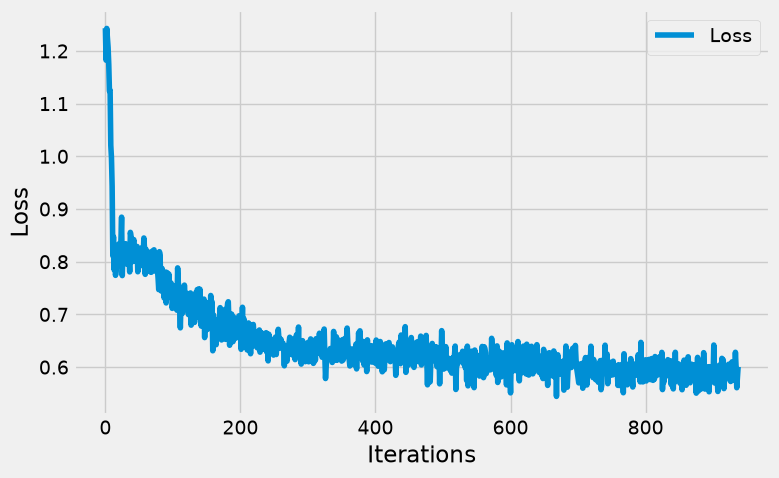

In [35]:
epochs = 1
outputs = []
losses = []

for epoch in range(epochs):
    for images, _ in train_loader:
        images = images.view(-1, 28 * 28).to(device)
        
        reconstructed = model(images)
        loss = loss_function(reconstructed, images)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        losses.append(loss.item())
    
    outputs.append((epoch, images, reconstructed))
    print(f"Epoch {epoch+1}/{epochs}, Loss: {loss.item():.6f}")

plt.style.use('fivethirtyeight')
plt.figure(figsize=(8, 5))
plt.plot(losses, label='Loss')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.legend()
plt.show()

### **Task 3**: Visualise reconstructions

Plot the original and reconstructed images side by side for 8 test examples. Then print the shape of the input, latent vector, and output to confirm the compression is working correctly.

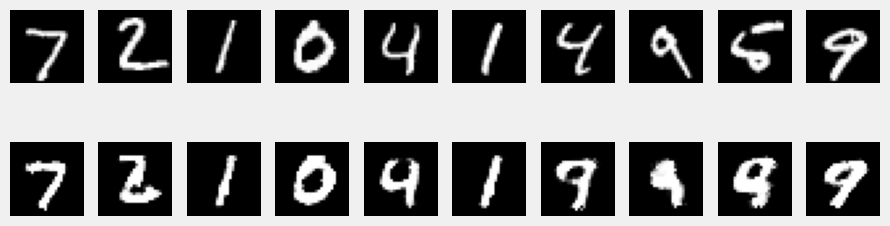

In [36]:
model.eval()
dataiter = iter(test_loader)
images, _ = next(dataiter)

images = images.view(-1, 28 * 28).to(device)
reconstructed = model(images)

fig, axes = plt.subplots(nrows=2, ncols=10, figsize=(10, 3))
for i in range(10):
    axes[0, i].imshow(images[i].cpu().detach().numpy().reshape(28, 28), cmap='gray')
    axes[0, i].axis('off')
    axes[1, i].imshow(reconstructed[i].cpu().detach().numpy().reshape(28, 28), cmap='gray')
    axes[1, i].axis('off')
plt.show()